# Robustness of the inference to sparse data

First, we need to observe how the downsmapling process is different from the backtracked distribution.

In [2]:
display("text/html", "<style>.container { width:100% !important; }</style>")

In [252]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM, StatsBase, Distributions

In [4]:
Plots.theme(:dao)

In [5]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [6]:
pal = cgrad(:tol_muted);
cpal = [pal[i] for i in 0.0:1/5:1]

In [7]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
read_data = filter(:nreads => !=(0), read_data)
# first split on classification
gd1 = groupby(read_data, :classification);

gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

classes = [gd_classes[i][1][!,:classification][2] for i in 1:length(gd_classes)]
classes = strip.(lowercase.(classes))
classes[10] = "marine hydrothermal vents"
classes[6] = "oral cavity"
classes[5] = "terrestrial soil"
classes[end] = "activated sludge"
classes;

Now need to pick an initial condition.

In [8]:
ind_choice = 2;
data = gd_classes[ind_choice];
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
small_to_large = sortperm(sizes);
ic_sys = sort(data[small_to_large[1]][!,:count],rev=true);

In [267]:
ic_sys;

# First make the big system and the small system.

## $\gamma=1$

In [233]:
small_sys = dsim.create_cell(0.42, 1, 3, 10^5, ic_sys, :pdf)
big_sys = dsim.create_cell(0.42, 1, 3, 10^6, small_sys, :pdf);

Now make the downsampled system.

In [234]:
probs = big_sys ./sum(big_sys);

In [235]:
function sample_counts(p::Vector{Float64}, N::Int)
    M = length(p)
    counts = zeros(Int, M)

    w = Weights(p)

    samples = sample(1:M, w, N)  # draw N samples at once

    for i in samples
        counts[i] += 1
    end
    
    sort!(counts, rev=true)
    counts = counts[counts .!=0]
    
    return counts
end

sample_counts (generic function with 1 method)

In [236]:
ds_sys = sample_counts(probs, 10^5);

In [237]:
sum(small_sys)

100000.0

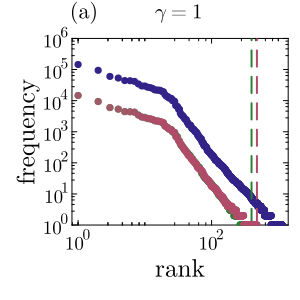

In [238]:
s1 = scatter(big_sys, label = L"full system, $N=10^6$", c = cpal[1])

scatter!(small_sys, label = L"back-tracked, $N=10^5$", c = cpal[3], alpha = 0.8)
plot!([length(small_sys),length(small_sys)], [0.1,10^7], ylims = [1,10^6], label = :none, c = cpal[3], linestyle = :dash, lw = 2)

scatter!(ds_sys, label = L"down-sampled, $N=10^5$", c = cpal[end-1], alpha = 0.8)
plot!([length(ds_sys),length(ds_sys)], [0.1,10^7], label = :none, c = cpal[end-1], linestyle = :dash, lw = 2)

scatter!(xaxis = :log10, yaxis = :log10)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :none)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(a) $\quad\quad\quad\gamma=1$", titleloc = :left, xlabel = "rank", ylabel = "frequency")

## $\gamma>1$

In [239]:
small_sys2 = dsim.create_cell(0.42, 1.2, 3, 10^5, ic_sys, :pdf)
big_sys2 = dsim.create_cell(0.42, 1.2, 3, 10^6, small_sys2, :pdf);

Now make the downsampled system.

In [240]:
probs2 = big_sys2 ./sum(big_sys2);

In [241]:
ds_sys2 = sample_counts(probs2, 10^5);

In [242]:
sum(small_sys2)

100000.0

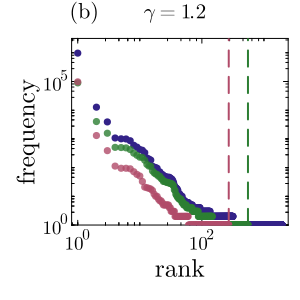

In [243]:
s2 = scatter(big_sys2, label = "full system", c = cpal[1])

scatter!(small_sys2, label = "back-tracked", c = cpal[3], alpha = 0.8)
plot!([length(small_sys2),length(small_sys2)], [0.1,10^7], ylims = [1,10^6.5], label = :none, c = cpal[3], linestyle = :dash, lw = 2)

scatter!(ds_sys2, label = "down-sampled", c = cpal[end-1], alpha = 0.8)
plot!([length(ds_sys2),length(ds_sys2)], [0.1,10^7], label = :none, c = cpal[end-1], linestyle = :dash, lw = 2)


scatter!(xaxis = :log10, yaxis = :log10)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :none)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(b) $\quad\quad\;\gamma=1.2$", titleloc = :left, xlabel = "rank", ylabel = "frequency")

## $\gamma<1$

In [244]:
small_sys3 = dsim.create_cell(0.42, 0.8, 3, 10^5, ic_sys, :pdf)
big_sys3 = dsim.create_cell(0.42, 0.8, 3, 10^6, small_sys3, :pdf);

Now make the downsampled system.

In [245]:
probs3 = big_sys3 ./sum(big_sys3);

In [246]:
ds_sys3 = sample_counts(probs3, 10^5);

In [247]:
sum(small_sys3)

100000.0

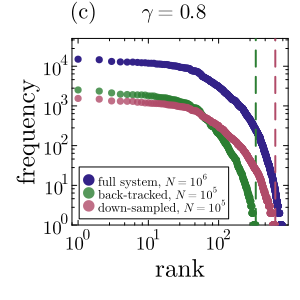

In [248]:
s3 = scatter(big_sys3, label = L"full system, $N=10^6$", c = cpal[1])

scatter!(small_sys3, label = L"back-tracked, $N=10^5$", c = cpal[3], alpha = 0.8)
plot!([length(small_sys3),length(small_sys3)], [0.1,10^5], ylims = [1,10^4.7], label = :none, c = cpal[3], linestyle = :dash, lw = 2)

scatter!(ds_sys3, label = L"down-sampled, $N=10^5$", c = cpal[end-1], alpha = 0.8)
plot!([length(ds_sys3),length(ds_sys3)], [0.1,10^5], label = :none, c = cpal[end-1], linestyle = :dash, lw = 2)

scatter!(xaxis = :log10, yaxis = :log10)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :bottomleft)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(c) $\quad\quad\;\gamma=0.8$", titleloc = :left, xlabel = "rank", ylabel = "frequency")

In [249]:
using Plots.Measures

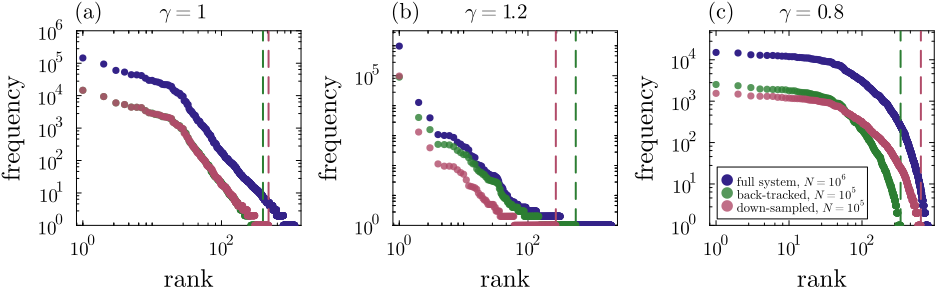

In [250]:
plot(s1,s2,s3, layout = (1,3), size = (950,300), bottom_margin = 10mm, top_margin = 3mm, left_margin = 5mm, right_margin = 2mm)
# savefig("")

# Data-informed robustness space

The median value of $\gamma=1.06$ with many values over the range $[0.95,1.2]$, and the median value of $\theta=0.42$ with many values over the range $[-1,1]$. We will pick 20 parameter points in this regime of the space and show the parameter drift.

I need to make the data that can be imported into a `sbatch` process in the CARC cluster. 

In [258]:
# γ_rands = rand(Uniform(0.95,1.2),20)
γ_rands;

In [259]:
# θ_rands = rand(Uniform(-1,1),20)
θ_rands;

In [260]:
γθ_df = DataFrame(γ = γ_rands, θ = θ_rands);

In [261]:
CSV.write("rand_γθ_df.csv", γθ_df)

"rand_γθ_df.csv"

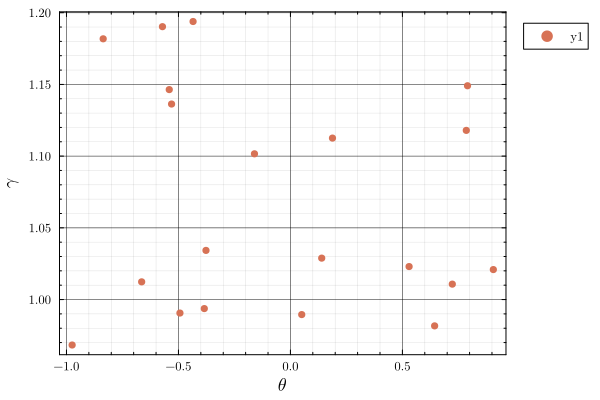

In [265]:
scatter(θ_rands, γ_rands, xlabel = L"\theta", ylabel = L"\gamma")

Now, we downsampled distributions for each parameter set which will be stored in the folder `ds_distributions`.

In [270]:
for i in 1:20
    # simulate full system size
    b_sys = dsim.create_cell(θ_rands[i], γ_rands[i], 1, 10^6, ic_sys, :pdf);
    # find probs of being in each species
    p_sys = b_sys ./sum(b_sys);
    # downsample
    d_sys = sample_counts(p_sys, 10^5);
    # save the downsample
    df_temp = DataFrame(ds_abundance = d_sys)
    CSV.write("./ds_distributions/ds_dist_$(i).csv", df_temp)
end